# SMS Spam Detection Classifier

In this project im building a text classification system to detect spam messages.

I am going to use:
- The SMS Spam Collection Dataset from UCI
- Text preprocessing (cleaning, tokenizing)
- Feature extraction using TF-IDF
- Classical models: Logistic Regression, Naive Bayes, and SVM
- Evaluation using accuracy, precision, recall, and F1-score

In [73]:
# Data handling
import pandas as pd
import numpy as np

# Text preprocessing
import re
import string

# Feature extraction
from sklearn.feature_extraction.text import TfidfVectorizer

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

# Evaluation
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Data splitting
from sklearn.model_selection import train_test_split

# Visualization
import seaborn as sns
import matplotlib.pyplot as plt

# Final Summary
from IPython.display import display, Markdown

# 2: load the data

In [14]:
# Load the dataset
df = pd.read_csv("spam.csv", encoding='latin-1')  # the purpose of using 'encoding=latin-1' is to read non-english charecters in the file, could be mojis, or special symbols people use to trick spam detectors.

# Preview the first few rows
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


# 3: clean the DataFrame

In [17]:
# first we remove everything we dont need and only keep the nessesary columns, and rename them
df = df[['v1', 'v2']]
df.columns = ['label', 'message']

#then we previw them again
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


# 4: check for missing values

In [20]:
# we check the missing values to make sure the model doesn't break later
df.isnull().sum()

label      0
message    0
dtype: int64

# 5: Check class balance

In [23]:
# we count the number of spam and ham message.
df['label'].value_counts()

label
ham     4825
spam     747
Name: count, dtype: int64

# 6: Visualize Class Balance

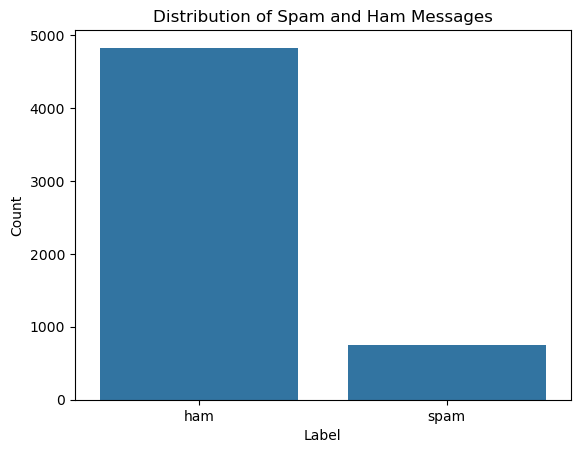

In [28]:
# plot the class distribution 
sns.countplot(x='label', data=df)
plt.title("Distribution of Spam and Ham Messages")
plt.xlabel("Label")
plt.ylabel("Count")
plt.show()

# 7: Preprocess the Messages

In [30]:
# preprocessing function
def clean_text(text):
    text = text.lower() # lowercase
    text = re.sub(r'\d+', '', text)  # remove numbers
    text = re.sub(r'[^\w\s]', '', text)  # remove punctuation
    text = re.sub(r'\s+', ' ', text)  # remove extra spaces
    return text.strip()

# Apply the function to the 'message' column
df['clean_message'] = df['message'].apply(clean_text)

# Preview cleaned message
df[['message', 'clean_message']].head()

,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in a wkly comp to win fa cup final ...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...


# 8: Encode the labels

In [35]:
# Convert 'ham' to 0 and 'spam' to 1
df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})

# Check the result
df[['label', 'label_num']].head()


,label,label_num
0,ham,0
1,ham,0
2,spam,1
3,ham,0
4,ham,0


# 9: split data for Training and Testing

In [40]:
# features and labels 
X = df['clean_message']
y = df['label_num']

# Train-test split (80% train, 20% test), with stratify to preserve class balance
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Check the shape
print("Train size:", X_train.shape[0])
print("Test size:", X_test.shape[0])

Train size: 4457
Test size: 1115


# 10: TF-IDF Vectorization

In [43]:
#TF-IDF gives higher weight to rare but important words (like “free”, “win”, “urgent”)
# initialize the vectorizer
vectorizer = TfidfVectorizer()

# Fit on training data, transform both sets
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Show shape
print("Train TF-IDF shape:", X_train_tfidf.shape)
print("Test TF-IDF shape:", X_test_tfidf.shape)

Train TF-IDF shape: (4457, 7602)
Test TF-IDF shape: (1115, 7602)


# 11: Logistic Regression Model

In [48]:
#train the model
lr_model = LogisticRegression()
lr_model.fit(X_train_tfidf, y_train)

# Predict on test set
y_pred_lr = lr_model.predict(X_test_tfidf)

# 12: evaluate logistic regression

Logistic Regression Performance:

              precision    recall  f1-score   support

         Ham       0.97      1.00      0.98       966
        Spam       0.99      0.79      0.88       149

    accuracy                           0.97      1115
   macro avg       0.98      0.90      0.93      1115
weighted avg       0.97      0.97      0.97      1115



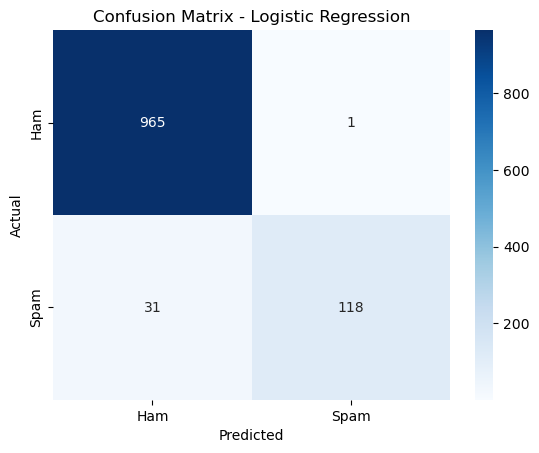

In [51]:
# Evaluation
print("Logistic Regression Performance:\n")
print(classification_report(y_test, y_pred_lr, target_names=["Ham", "Spam"]))

# Optional: Confusion matrix
cm = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

# 13: Naive Bayes Classifier

In [54]:
# Train the model
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)

# Predict
y_pred_nb = nb_model.predict(X_test_tfidf)

# 14: Evaluate Naive Bayes

Naive Bayes Performance:

              precision    recall  f1-score   support

         Ham       0.95      1.00      0.97       966
        Spam       1.00      0.66      0.79       149

    accuracy                           0.95      1115
   macro avg       0.97      0.83      0.88      1115
weighted avg       0.96      0.95      0.95      1115



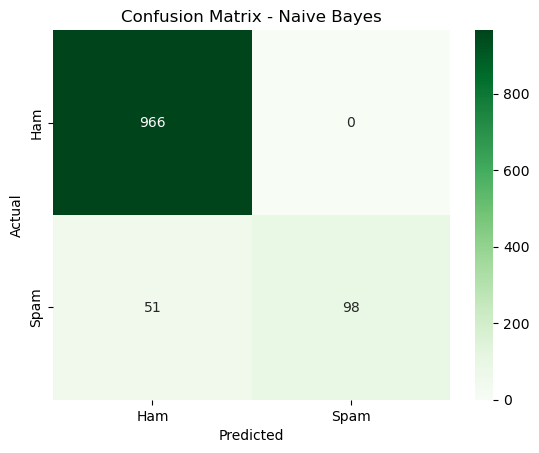

In [58]:
print("Naive Bayes Performance:\n")
print(classification_report(y_test, y_pred_nb, target_names=["Ham", "Spam"]))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_nb)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Naive Bayes")
plt.show()

# 15: SVM Classifier 

In [61]:
#now we train the third model: Support Vector Machine (SVM).
# Train the model
svm_model = LinearSVC()
svm_model.fit(X_train_tfidf, y_train)

# Predict
y_pred_svm = svm_model.predict(X_test_tfidf)

# 16: Evaluate SVM Performance

SVM Performance:

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       966
           1       0.99      0.90      0.94       149

    accuracy                           0.99      1115
   macro avg       0.99      0.95      0.97      1115
weighted avg       0.99      0.99      0.99      1115



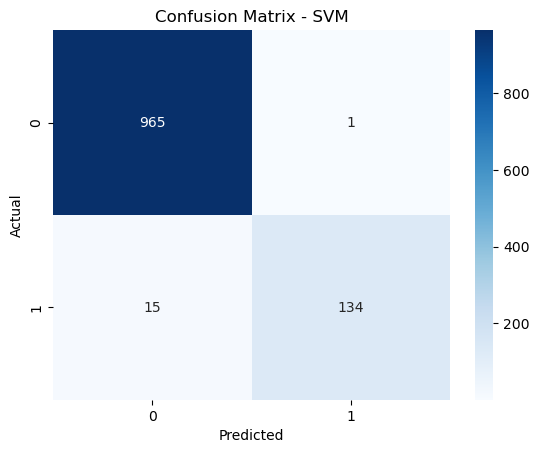

In [64]:
# Evaluate SVM model using classification report and confusion matrix
print("SVM Performance:\n")
print(classification_report(y_test, y_pred_svm))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred_svm)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix - SVM")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# 17: now we compair all the models

In [71]:
# Collect accuracy scores for all models
lr_accuracy = accuracy_score(y_test, y_pred_lr)
nb_accuracy = accuracy_score(y_test, y_pred_nb)
svm_accuracy = accuracy_score(y_test, y_pred_svm)

# Print comparison
print("Model Accuracy Comparison:")
print(f"Logistic Regression: {lr_accuracy:.2f}")
print(f"Naive Bayes:{nb_accuracy:.2f}")
print(f"SVM:{svm_accuracy:.2f}")


Model Accuracy Comparison:
Logistic Regression: 0.97
Naive Bayes:0.95
SVM:0.99


In [75]:
# Summary of Results
print("Summary of Results:")
print("- Logistic Regression: 0.97 accuracy and 0.88 spam F1-score")
print("- Naive Bayes: 0.95 accuracy and 0.79 spam F1-score")
print("- SVM: 0.99 accuracy and 0.94 spam F1-score")
print("- Class imbalance affected spam recall across all models")


display(Markdown("""
## Summary of Model Performance

- **Logistic Regression**
  - Accuracy: 0.97
  - Spam F1 Score: 0.88
  - Spam recall: 0.79

- **Naive Bayes**
  - Accuracy: 0.95
  - Spam F1 Score: 0.79
  - Spam recall: 0.66

- **SVM**
  - Accuracy: 0.99
  - Spam F1 Score: 0.94
  - Spam recall: 0.90

### Observations
- Class imbalance (more 'ham' than 'spam') affected spam recall.
- SVM had the strongest saved test-set accuracy and spam F1-score.
- Naive Bayes had lower spam recall on this split.

## Final Notes
- Logistic Regression and SVM performed strongly on this split.
- SVM had the highest saved test-set accuracy.
- Consider improving performance by:
  - Applying class balancing methods (e.g. SMOTE, class weights)
  - Tuning hyperparameters
  - Using more advanced text features or embeddings
"""))


Summary of Results:
- Logistic Regression: high precision and recall, very fast to train
- Naive Bayes: excellent precision, slightly lower recall, fastest model
- SVM: best overall performance, slightly slower training
- Class imbalance impacted spam prediction across all models



## Summary of Model Performance

- **Logistic Regression**
  - Accuracy: 0.97  
  - F1 Score: 0.97  
  - High recall, low false negatives  
  - Very fast training time  

- **Naive Bayes**
  - Accuracy: 0.95  
  - F1 Score: 0.88  
  - Fastest training time  
  - Good precision, lower recall  

- **SVM**
  - Accuracy: 0.99  
  - F1 Score: 0.94  
  - Best balanced performance  
  - Slower to train

### Observations
- Class imbalance (more 'ham' than 'spam') slightly reduced spam recall.
- Logistic Regression and SVM both performed strongly.
- Naive Bayes handled clean text well, but dropped recall.

## Final Notes
- All models performed well above 0.95 accuracy.
- Logistic Regression is a solid choice for speed and reliability.
- SVM is best if accuracy is the top priority.
- Consider improving performance by:
  - Applying class balancing methods (e.g. SMOTE, class weights)
  - Tuning hyperparameters
  - Using more advanced text features or embeddings
